# Part 2 — Reproducible traffic analytics
I-94 corridor | NUS SOC Smart City Traffic Intelligence

Open in Google Colab and choose Runtime → Run all. Upload the original Metro_Interstate_Traffic_Volume.csv when prompted. The final cell downloads capstone_part2.zip, containing the scripts, cleaned data, figures, findings, sample log and local Git history.


Find your working files in Colab. Click the folder icon on the left to open the Files pane. Refresh it and open capstone_part2_work → run_… → capstone_part2. Each run creates a fresh folder so you can inspect earlier runs in the same session. These files are temporary and can disappear when the runtime is reset.

In [1]:
from pathlib import Path
import os
import shutil
import subprocess
import sys
import tempfile

# Look for the original traffic CSV. Colab prompts you to upload it if it is missing.
raw_csv = Path(os.environ.get("TRAFFIC_CSV", str(Path("/content" if Path("/content").is_dir() else ".") / "Metro_Interstate_Traffic_Volume.csv"))).resolve()
if not raw_csv.exists():
    from google.colab import files
    uploaded = files.upload()
    if raw_csv.name not in uploaded:
        raise ValueError(f"Upload {raw_csv.name} and rerun this cell.")
    raw_csv.write_bytes(uploaded[raw_csv.name])

# Create a fresh working folder so an earlier run does not affect this one.
colab_files = Path("/content")
if colab_files.is_dir():
    # Colab's Files pane can browse everything under /content.
    work_root = colab_files / "capstone_part2_work"
    work_root.mkdir(exist_ok=True)
    workspace = Path(tempfile.mkdtemp(prefix="run_", dir=work_root))
else:
    workspace = Path(tempfile.mkdtemp(prefix="capstone_"))
project = workspace / "part2_python"
(project / "cli_app").mkdir(parents=True)
os.chdir(project)

def write(path, content):
    Path(path).write_text(content.strip() + "\n", encoding="utf-8")

def git(*args):
    return subprocess.run(["git", *args], check=True, capture_output=True, text=True)

# Stage the files for this task and record a Git snapshot with a descriptive message.
def commit(message, *paths):
    git("add", "--", *paths)
    git("commit", "-m", message)

# Run the same Python entry point you can use later from Windows Command Prompt.
def run(*args, expected=0):
    result = subprocess.run([sys.executable, "-m", "cli_app.main", *map(str, args)],
                            env={**os.environ, "PYTHONUTF8": "1"})
    if result.returncode != expected:
        raise RuntimeError(f"{args[0]} exited with {result.returncode}; expected {expected}")

# Start a local Git repository here. This step does not contact GitHub.
# This block sets up the generated part2_python folder so the notebook can record Git commits and prepare the files needed to run the project.
git("init", "-q")
git("config", "user.name", "Capstone Student")
git("config", "user.email", "capstone@local.invalid")
write(".gitignore", "__pycache__/\n*.pyc\n")
write("requirements.txt", "pandas>=2,<4\nnumpy>=1.24,<3\nmatplotlib>=3.7,<4")
write("cli_app/__init__.py", "# Command-line application package")

## Task 1 — Load, validate and clean the CSV
The pipeline checks that the CSV contains all nine required columns, standardises text labels, and validates the timestamps and numeric fields. It removes exact duplicates and retains one record per timestamp using the Part 1 weather-severity ranking. When scores tie, it uses the weather description and then the original row order. An independent SQLite query checks that the Python pipeline selected the same hourly records on the fields compared.

The pipeline saves the hourly baseline before imputation and holiday expansion so the Part 1 results can be reproduced. It then replaces flagged sensor readings with the median of valid readings from the same year and month. Holiday labels are applied to all recorded hours on the flagged dates. Missing hours and dates remain gaps in the dataset.


In [2]:
%%writefile config.py
"""Shared schema, ranking and thresholds."""
# These nine column names must be present before the pipeline can clean the CSV.
COLUMNS = ("holiday", "temp", "rain_1h", "snow_1h", "clouds_all",
           "weather_main", "weather_description", "date_time", "traffic_volume")
# The list starts at the lowest severity. Positions become scores starting from one.
ORDER = ("Clear", "Clouds", "Mist", "Haze", "Smoke", "Fog", "Drizzle",
         "Rain", "Snow", "Squall", "Thunderstorm")
RANK = {name: value for value, name in enumerate(ORDER, 1)}
# The Part 1 review identified these two zero-volume readings as sensor dropouts.
DROP_OUTS = ("2016-07-23 18:00:00", "2016-07-23 23:00:00")
SEVERE = {"Thunderstorm", "Snow", "Squall"}
LOW_VISIBILITY = {"Fog", "Mist", "Haze", "Smoke"}
CONGESTION = 5500

Writing config.py


In [3]:
%%writefile pipeline.py
"""Build and check a validated hourly dataset."""
from contextlib import closing
import logging
import sqlite3

import pandas as pd

from config import COLUMNS, DROP_OUTS, RANK

logger = logging.getLogger(__name__)


# Use WARNING when rows were affected and INFO when a check found no changes.
def change(n, action, reason):
    logger.log(logging.WARNING if n else logging.INFO, "%s %d rows | %s", action, n, reason)


def load_csv(path):
    try:
        # Read cells as text and preserve the literal holiday label None.
        raw = pd.read_csv(path, dtype="string", keep_default_na=False)
    except (FileNotFoundError, OSError, pd.errors.ParserError, pd.errors.EmptyDataError, UnicodeError) as exc:
        raise ValueError(f"Cannot read {path}: {exc}") from exc
    logger.info("Loaded %d rows and %d columns from %s", *raw.shape, path)
    # Validate the column names before doing any transformations.
    missing = set(COLUMNS) - set(raw)
    if missing or raw.empty:
        raise ValueError(f"Invalid schema or empty data. Missing columns: {sorted(missing)}")
    logger.info("Validated all nine required columns")
    return raw.loc[:, list(COLUMNS)].copy()


# Independently rank the same records in SQLite and compare with the Pandas result.
def reconcile(raw, hourly):
    cols = ["date_time", "weather_main", "temp", "traffic_volume"]
    rank = " ".join(f"WHEN '{name}' THEN {n}" for name, n in RANK.items())
    with closing(sqlite3.connect(":memory:")) as conn:
        raw[cols + ["weather_description", "source_row"]].to_sql("raw", conn, index=False)
        expected = pd.read_sql_query(f"""
            WITH ranked AS (
                SELECT *, ROW_NUMBER() OVER (
                    PARTITION BY date_time
                    ORDER BY CASE weather_main {rank} ELSE 0 END DESC,
                             weather_description, source_row
                ) AS rn FROM raw
            )
            SELECT date_time, weather_main, temp, traffic_volume
            FROM ranked WHERE rn = 1 ORDER BY date_time
        """, conn, parse_dates=["date_time"])
    pd.testing.assert_frame_equal(hourly[cols].reset_index(drop=True), expected, check_dtype=False)
    logger.info("SQLite reconciliation passed for %d hourly records", len(expected))


def impute(frame, field, invalid):
    invalid = invalid.fillna(True)
    # A year-month group keeps, for example, January 2014 separate from January 2015.
    months = frame["date_time"].dt.to_period("M")
    change(int(invalid.sum()), "Detected", f"invalid or missing {field}")
    for month in months[invalid].unique():
        group = months.eq(month)
        affected = group & invalid
        if affected.any():
            # Use only valid readings for the median, then replace just the flagged readings.
            median = frame.loc[group & ~invalid, field].median()
            if pd.isna(median):
                raise ValueError(f"No valid {field} in {month} for median imputation")
            frame.loc[affected, field] = median
            change(int(affected.sum()), "Imputed", f"{field} using the {month} median")
            logger.debug("%s median for %s = %.4f", field, month, median)


def build_hourly(path, baseline):
    raw = load_csv(path)
    # Remember the original CSV row position for the final tie-break.
    raw["source_row"] = range(len(raw))
    # Clean up spacing and capitalisation before comparing categories.
    for col in ("holiday", "weather_main", "weather_description"):
        cleaned = raw[col].str.strip().str.replace(r"\s+", " ", regex=True)
        cleaned = cleaned.str.lower() if col == "weather_description" else cleaned.str.title()
        fill = {"holiday": "None", "weather_main": "Unknown", "weather_description": ""}
        cleaned = cleaned.replace("", fill[col])
        change(int(raw[col].ne(cleaned).sum()), "Standardised", col)
        raw[col] = cleaned

    # Explicit formats preserve ambiguous day-first dates such as 02/10/2012.
    dates = pd.Series(pd.NaT, index=raw.index, dtype="datetime64[ns]")
    for fmt in ("%Y-%m-%d %H:%M:%S", "%Y-%m-%d %H:%M", "%d/%m/%Y %H:%M", "%d/%m/%Y %H:%M:%S"):
        pending = dates.isna()
        dates.loc[pending] = pd.to_datetime(raw.loc[pending, "date_time"].str.strip(), format=fmt, errors="coerce")
    valid = dates.notna() & dates.eq(dates.dt.floor("h"))
    change(int((~valid).sum()), "Dropped", "invalid or non-hourly timestamps")
    raw["date_time"] = dates
    raw = raw.loc[valid].copy()
    if raw.empty:
        raise ValueError("No valid hourly observations")
    logger.info("Parsed %d hourly timestamps", len(raw))

    for col in ("temp", "rain_1h", "snow_1h", "clouds_all", "traffic_volume"):
        values = pd.to_numeric(raw[col], errors="coerce").astype(float)
        change(int((values.isna() & raw[col].ne("")).sum()), "Marked missing", f"non-numeric {col}")
        raw[col] = values
    flags = raw.loc[raw["holiday"].ne("None")]
    holidays = flags.groupby(flags["date_time"].dt.normalize())["holiday"].max()
    # Remove identical records first. Rows with the same time can still differ in weather.
    exact = raw.duplicated(list(COLUMNS), keep="first")
    change(int(exact.sum()), "Dropped", "exact duplicates after standardisation")
    rows = raw.loc[~exact].copy()
    rows["weather_severity"] = rows["weather_main"].map(RANK).fillna(0).astype(int)
    # Put the highest weather score first within each timestamp. For tied scores, use
    # weather description and original row position.
    rows = rows.sort_values(["date_time", "weather_severity", "weather_description", "source_row"],
                            ascending=[True, False, True, True])
    # The first row in each timestamp group becomes the only observation for that hour.
    hourly = rows.drop_duplicates("date_time").copy()
    change(len(rows) - len(hourly), "Collapsed", "additional rows sharing a timestamp")
    assert hourly["date_time"].is_unique
    reconcile(raw, hourly)
    # Save a copy before imputation so Part 1 values can be reproduced.
    baseline.parent.mkdir(parents=True, exist_ok=True)
    hourly.drop(columns="source_row").to_csv(baseline, index=False)
    logger.info("Saved Part 1 baseline to %s", baseline)

    dropout = hourly["date_time"].isin(pd.to_datetime(list(DROP_OUTS)))
    for col, mask in (
        ("temp", hourly.temp.isna() | hourly.temp.le(0)),
        ("rain_1h", hourly.rain_1h.isna() | ~hourly.rain_1h.between(0, 9000)),
        ("snow_1h", hourly.snow_1h.isna() | hourly.snow_1h.lt(0)),
        ("clouds_all", hourly.clouds_all.isna() | ~hourly.clouds_all.between(0, 100)),
        ("traffic_volume", hourly.traffic_volume.isna() | hourly.traffic_volume.lt(0)
         | (dropout & hourly.traffic_volume.eq(0))),
    ):
        impute(hourly, col, mask)
    # Apply the holiday label to all recorded hours on that date.
    expanded = hourly.date_time.dt.normalize().map(holidays).fillna("None")
    change(int(hourly.holiday.ne(expanded).sum()), "Updated", "holiday labels across observed hours on flagged dates")
    hourly["holiday"] = expanded
    logger.info("Cleaned %d unique hours; %d flagged dates", len(hourly), len(holidays))
    return hourly.drop(columns="source_row")

Writing pipeline.py


In [4]:
commit("Task 1: validate and clean hourly traffic", ".gitignore", "requirements.txt",
       "cli_app/__init__.py", "config.py", "pipeline.py")

**Results.** The build reduced 48,204 raw rows to 40,575 unique hourly records by removing 17 exact duplicates and consolidating 7,612 additional records that shared a timestamp. It imputed 10 temperature readings, one rainfall reading, and two traffic counts. The pipeline.log records the number of rows affected and the reason for each change.

## Task 2 — Feature engineering
The raw CSV contained 9 columns. Task 1 added a weather-severity score during cleaning, so Task 2 began with 10 columns across 40,575 observed hours. Using pandas and NumPy, the pipeline extracted the hour and day of the week and created weekend and holiday flags. Sine and cosine encodings preserve the daily and weekly cycles, so the model can recognise that 23:00 is close to 00:00 and Sunday is close to Monday.

The pipeline converted temperature from Kelvin to Celsius and standardised temperature and cloud cover. Cloud cover adds detail to the weather label by recording the percentage of sky covered by clouds. The pipeline also created a binary indicator for each weather category and separate flags for severe weather and low visibility.

Three fields capture different definitions of congestion. The Part 1 SQL flag identifies hours with traffic above 5,500 vehicles. The Power BI bands classify traffic as Low, Medium, or High using fixed cutoffs of 4,500 and 5,500. The Part 2 quartile bands classify each hour relative to the cleaned dataset, using the 25th, 50th, and 75th percentiles to define Low, Medium, High, and Severe traffic.

In [5]:
%%writefile feature_engineering.py
"""Create reproducible time, weather and congestion features."""
import logging

import numpy as np
import pandas as pd

from config import CONGESTION, LOW_VISIBILITY, SEVERE

logger = logging.getLogger(__name__)


def engineer(frame):
    logger.info("Before features: %d rows, %d columns", *frame.shape)
    out = frame.copy()
    # Pull the clock hour and day of week from the timestamp. Monday is 0 and Sunday is 6.
    out["hour"] = out.date_time.dt.hour
    out["day_of_week"] = out.date_time.dt.dayofweek
    out["is_weekend"] = out.day_of_week.ge(5).astype(int)
    out["is_holiday"] = out.holiday.ne("None").astype(int)
    # Sine and cosine make the ends of a cycle meet, so 23:00 is close to midnight.
    for col, period in (("hour", 24), ("day_of_week", 7)):
        angle = 2 * np.pi * out[col] / period
        out[f"{col}_sin"] = np.sin(angle)
        out[f"{col}_cos"] = np.cos(angle)
    out["temp_c"] = out.temp - 273.15
    out["is_low_visibility"] = out.weather_main.isin(LOW_VISIBILITY).astype(int)
    out["is_severe_weather"] = out.weather_main.isin(SEVERE).astype(int)
    # Standardise both fields by subtracting the mean and dividing by the population SD.
    for col in ("temp_c", "clouds_all"):
        mean, sd = out[col].mean(), out[col].std(ddof=0)
        out[f"{col}_z"] = (out[col] - mean) / sd if sd > 0 else 0.0
        logger.debug("%s scaling mean %.4f and SD %.4f", col, mean, sd)
    # Keep the fixed Part 1 threshold and Power BI bands alongside the Part 2 categories.
    volume = out.traffic_volume
    out["is_congested_fixed"] = volume.gt(CONGESTION).astype(int)
    out["traffic_category_bi"] = np.select([volume.lt(4500), volume.le(CONGESTION)],
                                           ["Low", "Medium"], default="High")
    # Use the 25th, 50th and 75th percentiles as cutoffs for the four congestion classes.
    q1, q2, q3 = volume.quantile([.25, .5, .75])
    logger.debug("Congestion quartiles Q1/Q2/Q3 = %.2f / %.2f / %.2f", q1, q2, q3)
    out["congestion_category"] = np.select([volume.le(q1), volume.le(q2), volume.le(q3)],
                                            ["Low", "Medium", "High"], default="Severe")
    # One-hot encoding creates a separate 0/1 column for each weather label.
    out = pd.concat([out, pd.get_dummies(out.weather_main, prefix="weather", dtype=int)], axis=1)
    logger.info("After features: %d rows, %d columns", *out.shape)
    return out

Writing feature_engineering.py


In [6]:
commit("Task 2: engineer hourly and weather features", "feature_engineering.py")

Results. Feature engineering added 27 columns, bringing the final dataset to 37 columns while retaining all 40,575 hourly records. The pipeline records the starting and ending dimensions at INFO and the scaling statistics and quartile cutoffs at DEBUG.

## Task 3 — Matplotlib traffic figures

Four Matplotlib figures were generated from the cleaned hourly dataset to examine traffic by hour, compare weekday and weekend patterns, and explore how traffic varies with temperature and weather. The weather chart reports the number of observations alongside each category average. The path of each saved figure is recorded in `pipeline.log`.

In [7]:
%%writefile visualizations.py
"""Plot the cleaned hourly data."""
import logging

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

logger = logging.getLogger(__name__)


def save_figures(frame, folder):
    folder.mkdir(parents=True, exist_ok=True)

    # Use the same layout, save and log steps for each figure.
    def save(fig, name):
        path = folder / name
        fig.tight_layout()
        fig.savefig(path, dpi=150, facecolor="white")
        plt.close(fig)
        logger.info("Saved figure: %s", path)

    fig, ax = plt.subplots(figsize=(8, 3.8))
    # Average all observations at each clock hour to find the daily traffic profile.
    hourly = frame.groupby("hour").traffic_volume.mean()
    ax.bar(hourly.index, hourly, color="#147C83")
    ax.set(title="Average traffic by hour", xlabel="Local hour", ylabel="Vehicles per hour", xticks=range(0,24,2))
    save(fig, "01_hourly_demand.png")

    fig, ax = plt.subplots(figsize=(8, 3.8))
    # Plot weekday and weekend averages separately so their peak hours can be compared.
    for day, label, color in [(0, "Weekday", "#155B77"), (1, "Weekend", "#D68041")]:
        group = frame.loc[frame.is_weekend.eq(day)].groupby("hour").traffic_volume.mean()
        ax.plot(group.index, group, label=label, color=color, linewidth=2)
    ax.set(title="Weekday and weekend traffic", xlabel="Local hour", ylabel="Vehicles per hour", xticks=range(0,24,2))
    ax.legend(frameon=False)
    save(fig, "02_weekday_weekend.png")

    fig, ax = plt.subplots(figsize=(8, 4))
    # Each point pairs Celsius temperature with the volume recorded in that hour.
    ax.scatter(frame.temp_c, frame.traffic_volume, s=5, alpha=.12, color="#155B77", edgecolors="none")
    ax.set(title="Temperature and traffic", xlabel="Temperature (°C)", ylabel="Vehicles per hour")
    save(fig, "03_temperature_traffic.png")

    fig, ax = plt.subplots(figsize=(8, 4.3))
    # Add counts to the weather labels so rare conditions are visible beside their averages.
    groups = frame.groupby("weather_main").traffic_volume.agg(["mean", "size"]).sort_values("mean")
    labels = [f"{name} (n={count:,})" for name, count in groups["size"].items()]
    ax.barh(labels, groups["mean"], color="#147C83")
    ax.set(title="Average traffic by retained weather condition", xlabel="Vehicles per observed hour")
    save(fig, "04_weather_traffic.png")

Writing visualizations.py


The full Part 2 dataset shows an afternoon peak at **16:00**, averaging **5,708.61 vehicles per hour**. Weekday traffic also peaked at **16:00**, while weekend traffic peaked earlier at **13:00**. This difference supports using separate hourly baselines for weekdays and weekends. For a direct comparison with the Part 1 Power BI dashboard, the pre-imputation data was filtered to **2017**. It reproduced the dashboard’s **16:00 peak of 5,834.37 vehicles per hour**.

The temperature scatter plot shows substantial variation in traffic at similar temperatures, consistent with the weak positive correlation in the cleaned data (**Pearson’s r = 0.140**). Some plotted values may differ from Power BI because Part 2 replaces flagged sensor readings. Both analyses found the highest average traffic under **Clouds (3,616.71 vehicles per hour)** and the lowest under **Squall (420 vehicles per hour)**. The Squall average reflects **one recorded hour**, so it provides limited evidence about typical traffic during squalls.


In [8]:
commit("Task 3: save four traffic visualisations", "visualizations.py")

## Task 4 — Mini traffic analytics application
I developed a Python command-line application that uses the cleaned hourly I-94 dataset. It supports four commands. query retrieves traffic and weather for a specific timestamp, peak ranks the busiest hours by day type, compare summarises weekday and weekend traffic, and recommend identifies a lower-traffic departure window..


In [9]:
%%writefile cli_app/cli.py
"""Query the processed traffic dataset."""
from datetime import datetime
import logging

logger = logging.getLogger(__name__)


def register(commands):
    # Register the command names and arguments that users can type.
    query = commands.add_parser("query", help="Look up an observed local timestamp")
    query.add_argument("timestamp", help="YYYY-MM-DD HH:MM")
    peak = commands.add_parser("peak", help="Rank hours by average traffic")
    peak.add_argument("--day-type", choices=["weekday", "weekend"], default="weekday")
    peak.add_argument("--top", type=int, default=3)
    commands.add_parser("compare", help="Compare weekday with weekend traffic")
    recommend = commands.add_parser("recommend", help="Find a lower-traffic travel window")
    recommend.add_argument("--day-type", choices=["weekday", "weekend"], default="weekday")
    recommend.add_argument("--start", type=int, default=7)
    recommend.add_argument("--end", type=int, default=19)
    recommend.add_argument("--weather")


def summary(group):
    return group.traffic_volume.agg(average_vehicles="mean", observed_hours="size")


def answer(args, frame):
    if args.command == "query":
        try:
            # Check the requested date and time before looking up a row.
            timestamp = datetime.strptime(args.timestamp, "%Y-%m-%d %H:%M")
        except ValueError as exc:
            raise ValueError("Use YYYY-MM-DD HH:MM for the timestamp") from exc
        found = frame.loc[frame.date_time.eq(timestamp)]
        if found.empty:
            return f"No observation at {timestamp:%Y-%m-%d %H:%M}."
        row = found.iloc[0]
        return (f"{timestamp:%Y-%m-%d %H:%M}: {row.traffic_volume:,.0f} vehicles, "
                f"{row.weather_main}, {row.temp_c:.2f} °C, traffic band {row.traffic_category_bi}.")
    # Summarise the average and number of observations for each day type.
    if args.command == "compare":
        day_type = frame.is_weekend.map({0: "Weekday", 1: "Weekend"})
        return summary(frame.groupby(day_type)).round(2).to_string()
    subset = frame.loc[frame.is_weekend.eq(int(args.day_type == "weekend"))]
    # Rank hours from highest to lowest historical average volume.
    if args.command == "peak":
        if not 1 <= args.top <= 24:
            raise ValueError("--top must be between 1 and 24")
        return summary(subset.groupby("hour")).nlargest(args.top, "average_vehicles").round(2).to_string()
    if not 0 <= args.start < args.end <= 24:
        raise ValueError("Use 0 <= --start < --end <= 24")
    subset = subset.loc[subset.hour.between(args.start, args.end - 1)]
    if args.weather:
        subset = subset.loc[subset.weather_main.str.casefold().eq(args.weather.casefold())]
    profile = summary(subset.groupby("hour"))
    # Only recommend hours backed by at least 20 observations.
    eligible = profile.loc[profile.observed_hours.ge(20)]
    if eligible.empty:
        return "No eligible hour has at least 20 observations for these filters."
    hour = int(eligible.average_vehicles.idxmin())
    row = eligible.loc[hour]
    return (f"Consider {hour:02d}:00–{hour + 1:02d}:00 for a {args.day_type} trip. "
            f"Historical mean: {row.average_vehicles:,.0f} vehicles across "
            f"{int(row.observed_hours):,} observations.")

Writing cli_app/cli.py


In [10]:
%%writefile cli_app/main.py
"""Build the project or run a traffic query."""
import argparse
import logging
from pathlib import Path

import pandas as pd

from . import cli
import feature_engineering
import pipeline

logger = logging.getLogger(__name__)


# Set up console and file logging at the entry point so all modules use the same format.
def configure_logging(path, debug):
    path.parent.mkdir(parents=True, exist_ok=True)

    formatter = logging.Formatter(
        "%(asctime)s | %(levelname)s | %(name)s | %(message)s"
    )

    console = logging.StreamHandler()
    log_file = logging.FileHandler(path, encoding="utf-8")
    for handler in (console, log_file):
        handler.setFormatter(formatter)

    # Configure logging once at the CLI entry point for all modules.
    logging.basicConfig(
        level=logging.DEBUG if debug else logging.INFO,
        handlers=[console, log_file],
        force=True,
    )


class LoggedParser(argparse.ArgumentParser):
    def error(self, message):
        raise ValueError(message)


def main():
    parser = LoggedParser(description="I-94 hourly traffic analytics")
    parser.add_argument("--debug", action="store_true")
    parser.add_argument("--data", type=Path, default=Path("data/processed/Metro_Interstate_Clean.csv"))
    parser.add_argument("--log", type=Path, default=Path("pipeline.log"))
    commands = parser.add_subparsers(dest="command", required=True)
    build = commands.add_parser("build", help="Clean data, engineer features and save charts")
    build.add_argument("csv", type=Path)
    cli.register(commands)
    try:
        args = parser.parse_args()
    except ValueError as exc:
        configure_logging(Path("pipeline.log"), False)
        logger.error("Invalid arguments: %s", exc)
        return 2
    configure_logging(args.log, args.debug)
    logger.info("Command invoked: %s", vars(args))
    try:
        # The build command runs cleaning, feature engineering and figure generation in order.
        if args.command == "build":
            baseline = args.data.with_name("traffic_hourly_baseline.csv")
            frame = feature_engineering.engineer(pipeline.build_hourly(args.csv, baseline))
            args.data.parent.mkdir(parents=True, exist_ok=True)
            frame.to_csv(args.data, index=False)
            logger.info("Saved feature dataset to %s", args.data)
            from visualizations import save_figures
            save_figures(frame, Path("figures"))
        else:
            frame = pd.read_csv(args.data, parse_dates=["date_time"])
            # Print the answer requested by the user. Progress and errors go through the logger.
            print(cli.answer(args, frame))
        return 0
    except (OSError, ValueError, KeyError, AssertionError, ImportError) as exc:
        logger.error("%s failed: %s", args.command, exc, exc_info=args.command == "build")
        return 2


if __name__ == "__main__":
    raise SystemExit(main())

Writing cli_app/main.py


In [11]:
commit("Task 4: implement the logged traffic CLI", "cli_app/main.py", "cli_app/cli.py")

In [12]:
# Generate the cleaned data and plots before testing the commands that read them.
run("build", raw_csv)
run("query", "2017-01-02 16:00")
run("peak", "--day-type", "weekday", "--top", 3)
run("compare")
run("recommend", "--day-type", "weekday", "--start", 7, "--end", 19)
# This command should fail gracefully. The notebook expects exit status 2.
run("query", "invalid-date", expected=2)

In [13]:
from pathlib import Path

log_text = Path("pipeline.log").read_text(encoding="utf-8")
checks = [
    "Loaded 48204 rows and 9 columns",
    "Before features:",
    "After features:",
    "Saved figure:",
    "query failed: Use YYYY-MM-DD HH:MM",
]

for check in checks:
    print(f"{'FOUND' if check in log_text else 'MISSING'} — {check}")

FOUND — Loaded 48204 rows and 9 columns
FOUND — Before features:
FOUND — After features:
FOUND — Saved figure:
FOUND — query failed: Use YYYY-MM-DD HH:MM


The recommendation command filters observations by day type, travel hours, and optional weather. It ranks eligible one-hour windows by average recorded traffic and requires at least 20 matching observations per window to limit reliance on small samples. For weekday travel between 07:00 and 19:00 across all weather conditions, it recommended 10:00–11:00, with an average of 4,401 vehicles per hour across 1,216 observations. This historical-average approach provides a baseline for the model-based recommendations in Part 3.

I tested all four commands and confirmed that a malformed timestamp produced a clear error message. I also verified that pipeline.log recorded the CSV load, the dataset dimensions before and after feature engineering, figure-saving messages, and the expected invalid-timestamp error.

## Task 5 — Validation and Reproducibility

I used the pre-imputation hourly baseline to reproduce all seven Part 1 benchmarks, including 40,575 observed hours, 13,364 clear-weather hours, and the 2017 average of 5,834.37 vehicles per hour at 16:00. I used the cleaned dataset to calculate the Part 2 findings, display the four charts with their interpretations, and prepare the data for Part 3.

The notebook generates a Markdown findings report and a `README.md` that explains how to run the pipeline and CLI, interpret the logs, and reproduce the results. The fifth local Git commit records the documentation, figures, log, and processed data.

,Metric,Part 1 benchmark,Reproduced
0,Observed hours,40575.00,40575.00
1,Clear hours,13364.00,13364.00
2,Congested hours,6107.00,6107.00
3,Clear and congested hours,1762.00,1762.00
4,Average traffic,3290.65,3290.65
5,Valid average temperature (°C),8.24,8.24
6,2017 average traffic at 16:00,5834.37,5834.37


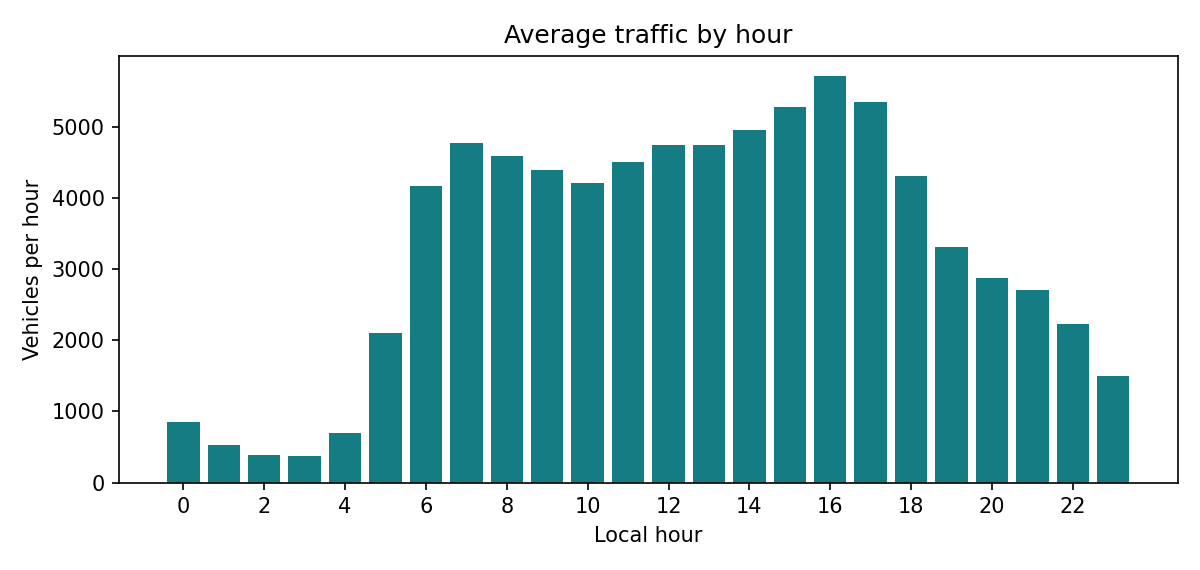

The full-period hourly profile peaks at 16:00, averaging 5,709 vehicles.

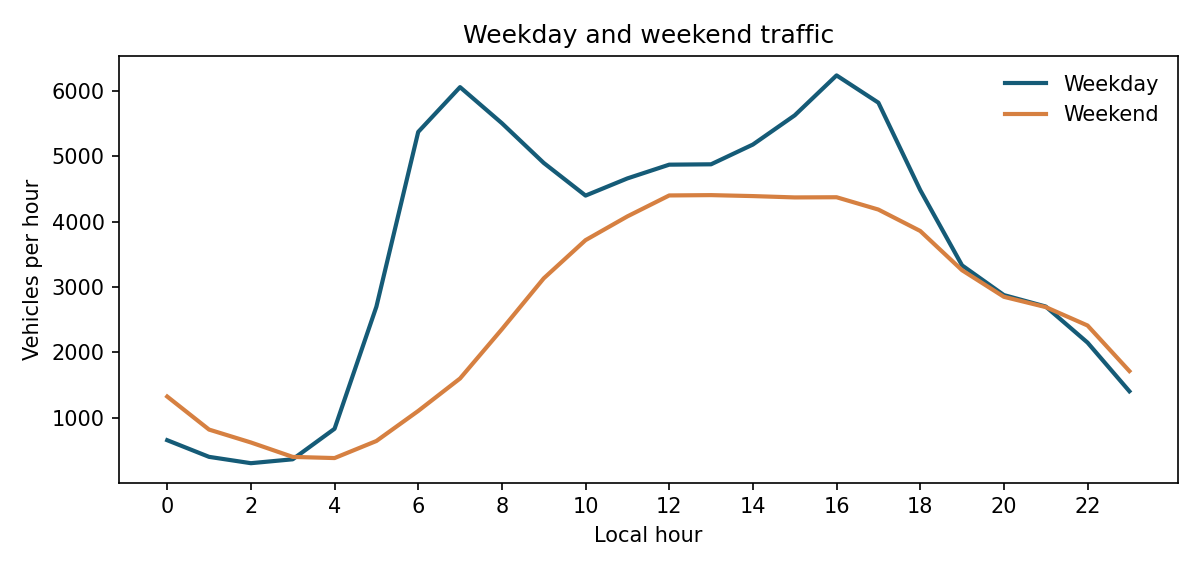

Weekday traffic peaks at 16:00 and weekend traffic peaks at 13:00. Compare each hour against its own day type.

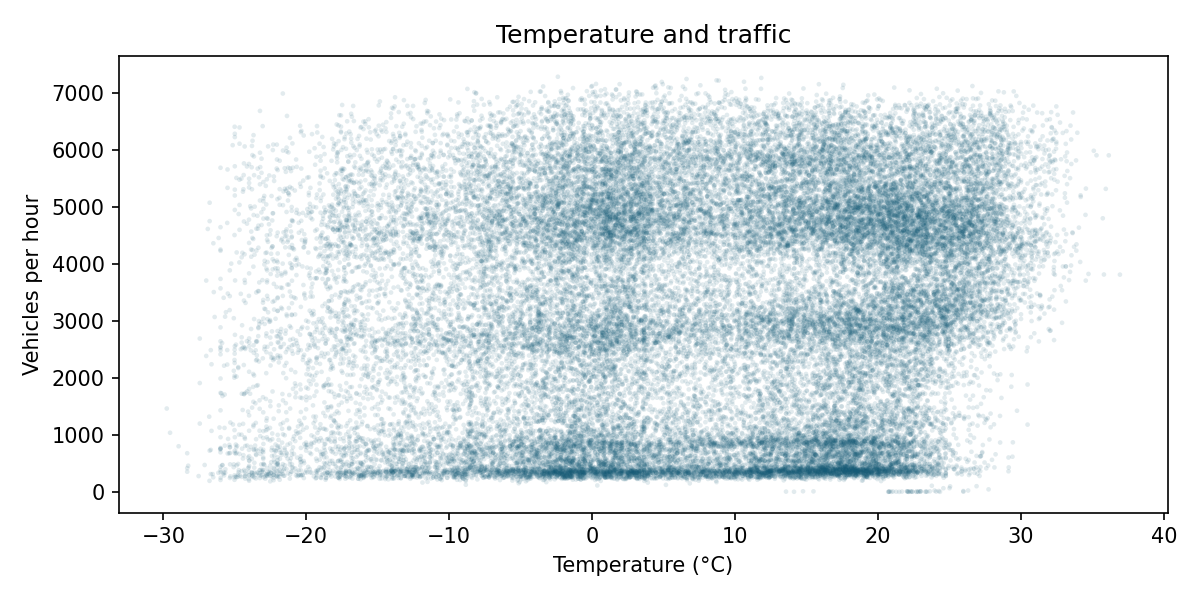

The scatter is broad, with Pearson r = +0.140. Clock hour and season can influence the association.

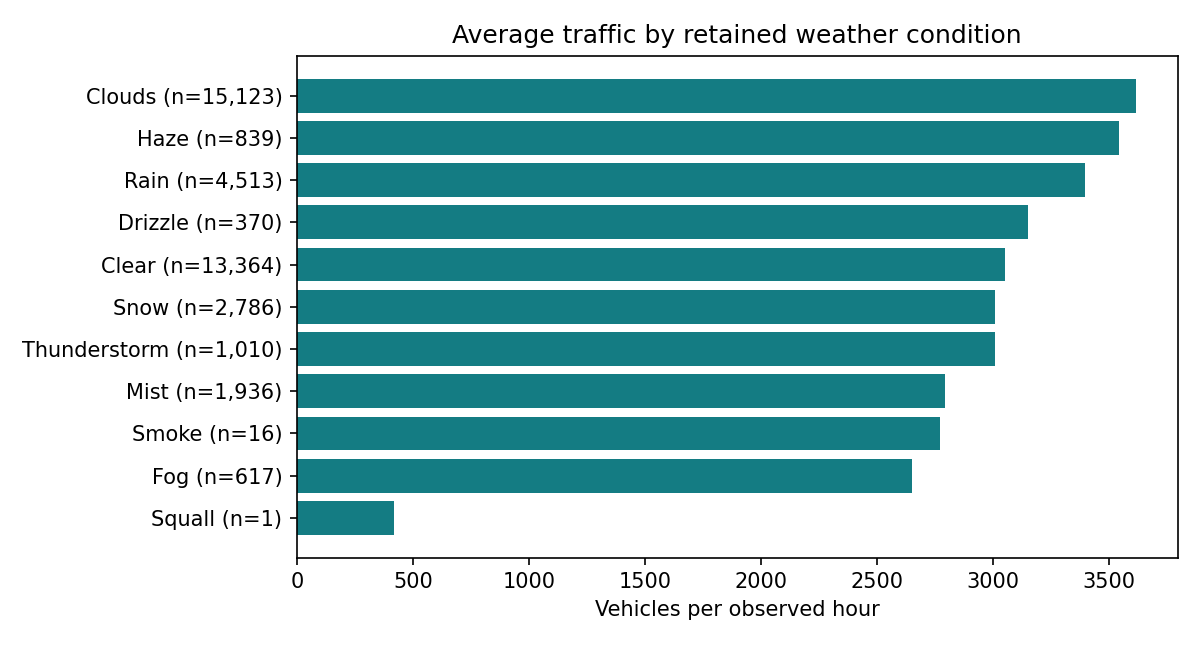

Clouds has the highest mean and Squall has the lowest. The lowest category has 1 hour(s), so account for sample size.

**Local Git history**

'4da4db1 Task 5: document reproducibility and capture verified outputs\n58fd858 Task 4: implement the logged traffic CLI\nb633e0e Task 3: save four traffic visualisations\n59c4a31 Task 2: engineer hourly and weather features\n7fbc69b Task 1: validate and clean hourly traffic\n'

In [14]:
import math
import pandas as pd
from IPython.display import Image, Markdown, display

# Use the pre-imputation data for Part 1 checks and the cleaned data for Part 2.
baseline = pd.read_csv("data/processed/traffic_hourly_baseline.csv", parse_dates=["date_time"])
clean = pd.read_csv("data/processed/Metro_Interstate_Clean.csv", parse_dates=["date_time"])
assert len(clean) == 40_575 and clean.date_time.is_unique
clear = baseline.weather_main.eq("Clear")
congested = baseline.traffic_volume.gt(5500)
hour_16 = baseline.date_time.dt.hour.eq(16) & baseline.date_time.dt.year.eq(2017)
# Compare each measured result with its known SQL or Power BI benchmark.
checks = [
    ("Observed hours", 40575, len(baseline)),
    ("Clear hours", 13364, clear.sum()),
    ("Congested hours", 6107, congested.sum()),
    ("Clear and congested hours", 1762, (clear & congested).sum()),
    ("Average traffic", 3290.65, round(baseline.traffic_volume.mean(), 2)),
    ("Valid average temperature (°C)", 8.24, round(baseline.loc[baseline.temp.gt(0), "temp"].mean() - 273.15, 2)),
    ("2017 average traffic at 16:00", 5834.37, round(baseline.loc[hour_16, "traffic_volume"].mean(), 2)),
]
# Stop the notebook if a benchmark does not match so the discrepancy can be reviewed.
assert all(math.isclose(expected, actual, rel_tol=0, abs_tol=1e-8)
           for _, expected, actual in checks), checks
display(pd.DataFrame(checks, columns=["Metric", "Part 1 benchmark", "Reproduced"]))

profile = clean.groupby("hour").traffic_volume.mean()
day = clean.groupby(["is_weekend", "hour"]).traffic_volume.mean()
weather = clean.groupby("weather_main").traffic_volume.agg(["mean", "size"]).sort_values("mean")
corr = clean.temp_c.corr(clean.traffic_volume)
# Explain what each chart shows, including the limits of rare weather categories.
notes = [
    f"The full-period hourly profile peaks at {profile.idxmax():02d}:00, averaging {profile.max():,.0f} vehicles.",
    f"Weekday traffic peaks at {day.loc[0].idxmax():02d}:00 and weekend traffic peaks at {day.loc[1].idxmax():02d}:00. Compare each hour against its own day type.",
    f"The scatter is broad, with Pearson r = {corr:+.3f}. Clock hour and season can influence the association.",
    f"{weather.index[-1]} has the highest mean and {weather.index[0]} has the lowest. The lowest category has {int(weather.iloc[0]['size']):,} hour(s), so account for sample size.",
]
figures = sorted(Path("figures").glob("*.png"))
assert len(figures) == len(notes)
for figure, note in zip(figures, notes):
    display(Image(filename=str(figure), width=700))
    display(Markdown(note))

# Write a short report from the observed results so it can travel with the scripts.
report = f'''# Part 2 Methodology and Findings

## Purpose and data
Create a reproducible hourly dataset and tools for monitoring traffic on the I-94 corridor. The Part 1 source contained 48,204 rows and nine columns. This pipeline keeps {len(clean):,} unique hourly observations using the same weather ranking as SQL and Power BI.

## Method
Validate the schema, standardise categories, parse local timestamps, remove exact duplicates and select the highest-ranked weather label per hour. Impute invalid temperature, extreme rainfall and documented traffic dropouts with year-month medians. Apply the holiday label across observed hours on each flagged date. Preserve gaps, including September 2014 through May 2015.

Time features cover clock hour, weekday, weekend and cyclical encodings. Weather features include one-hot labels, severity and visibility. Celsius temperature and cloud cover are standardised. Congestion quartiles are stored separately from the fixed SQL threshold and Power BI bands.

## Figure findings
''' + "\n".join(f"{i}. {note}" for i, note in enumerate(notes, 1)) + '''

## Reconciliation and limitations
The pre-imputation baseline reproduced the Part 1 totals and the Power BI 2017 16:00 mean of 5,834.37 vehicles. Part 2 imputations can change processed means. This historical dataset represents one corridor. Use current counts and matched hours when applying travel recommendations. For Part 3 evaluation, fit scaling and thresholds on training data and exclude traffic-derived categories from predictors.
'''
write("Methodology_and_Findings.md", report)
write("README.md", '''
# Capstone Part 2 Traffic Analytics

## Run
Install dependencies with python -m pip install -r requirements.txt.
Run python -m cli_app.main build /path/to/Metro_Interstate_Traffic_Volume.csv.
Pass --debug before build to include monthly medians, scaling parameters and quartiles.

## Project structure
- pipeline.py validates, deduplicates and imputes the hourly data.
- feature_engineering.py creates model-ready features.
- visualizations.py produces four PNG plots.
- cli_app/main.py configures logging and runs the build and CLI.
- cli_app/cli.py contains the four traffic queries.
- data/processed/Metro_Interstate_Clean.csv is the Part 3 handoff.
- data/processed/traffic_hourly_baseline.csv preserves the Part 1 comparison.
- Methodology_and_Findings.md and pipeline.log document a completed run.

## Commands
    python -m cli_app.main query "2017-01-02 16:00"
    python -m cli_app.main peak --day-type weekday --top 3
    python -m cli_app.main compare
    python -m cli_app.main recommend --day-type weekday --start 7 --end 19 --weather Clear

## Logging
The entry point configures console and file handlers for the traffic package.
The default file is pipeline.log. Each line has timestamp, level, module and message.
INFO records loads, commands, shapes and outputs. WARNING records cleaning changes and reasons.
ERROR records failures. DEBUG logs intermediate values only when enabled.
User-facing CLI answers go to standard output.

## Data contract
Weather scores run from Thunderstorm (11), Squall (10), Snow (9), Rain (8),
Drizzle (7), Fog (6), Smoke (5), Haze (4), Mist (3), Clouds (2), and Clear (1)
to other weather (0). Break ties by weather description and original row order.
Quartile targets are Low through Q1, Medium through Q2, High through Q3,
and Severe above Q3. For Part 3, recompute thresholds and scaling from training
data and omit target-derived variables from model predictors.

The project includes five local Git commits. Use git log --oneline to review them.
Publish to your own GitHub repository if submitting by repository link.
''')
# Save the documentation and genuine run outputs in the fifth Git commit.
commit("Task 5: document reproducibility and capture verified outputs", "README.md",
       "Methodology_and_Findings.md", "pipeline.log", "figures", "data/processed")
display(Markdown("**Local Git history**"))
display(git("log", "--oneline").stdout)


## Download the Part 2 Submission Folder

I packaged the generated `part2_python` folder as `capstone_part2.zip`. The ZIP includes the hidden `.git` folder, so the local commit history is available after extraction. I kept the original CSV separate. To run the command-line application, extract the ZIP first and run the commands from inside `part2_python`.

The final cell displays the locations of the project folder and ZIP. If the download does not start automatically, use the path shown in the output to find the ZIP in Colab’s **Files** pane.

For the GitHub submission, I’ll place this notebook and the methodology PDF alongside the generated files in `part2_python`.

In [15]:
# Zip the whole project folder, including the hidden .git folder with its commit history.
archive = Path(shutil.make_archive(str(workspace / "capstone_part2"), "zip",
                                   root_dir=workspace, base_dir=project.name))
# Show where the generated files live before the browser download starts.
display(Markdown(
    f"**Project files** `{project}`  " + "\n"
    f"**Submission ZIP** `{archive}`"
))
try:
    from google.colab import files
except ImportError:
    display(archive)
else:
    # In Colab, send the finished ZIP to the browser as a download.
    files.download(str(archive))

**Project files** `/content/capstone_part2_work/run_ljxtf5ka/part2_python`  
**Submission ZIP** `/content/capstone_part2_work/run_ljxtf5ka/capstone_part2.zip`

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>